# 经典深度调制识别模型对比实验讲义
## CCES-ResNet / DAE / CLDNN2 / MCLDNN / PET-CGGDNN（PyTorch 版）

**前置知识**：请先完成《RML2016.10a 调制识别零基础讲义》（掌握数据加载、预处理、训练评估流程）。本讲义直接复用其中的数据处理代码，**聚焦 5 个经典模型的结构原理与横向对比**。

---

### 🎯 学习目标
1. 理解 5 篇代表作的网络设计思想（每个模型一段"人话"讲解 + 结构图）；
2. 把网上找到的 Keras 代码"翻译"成能跑的 PyTorch 代码（科研必备技能）；
3. 产出论文对比实验的两大标配图：**各信噪比下的准确率曲线** + **混淆矩阵对比**。

### 📊 五模型速览

| 模型 | 出处 | 输入 | 核心结构 | 一句话思想 |
|---|---|---|---|---|
| **CCES-ResNet** | Ma et al. [46] | IQ (2×128) | 2D-CNN + 残差连接 | 用循环相关熵谱(CCES)抗脉冲噪声，ResNet 残差防梯度消失 |
| **DAE** | Ke et al. [32] | 幅度/相位 (128×2) | LSTM 编码器 + DNN 分类头 + **解码器重构** | 用"重构输入"当辅助任务，逼网络学到更本质的特征 |
| **CLDNN2** | Liu et al. [44] | IQ (2×128) | CNN → LSTM → DNN | CNN 提局部特征、LSTM 串起时序、DNN 分类，三段式流水线 |
| **MCLDNN** | Xu et al. [79] | I/Q 联合 + I 路 + Q 路 | 多通道 CNN → LSTM → DNN | 把 IQ 当"多视图"：联合视图 + 单路视图分别提特征再融合 |
| **PET-CGGDNN** | Zhang et al. [86] | IQ (128×2) | **多尺度并行 CNN** → GRU → DNN | 用不同大小的卷积核并行捕捉多尺度时序特征 |

> ⚠️ **诚实声明（论文写作时也要这样写）**：CCES-ResNet 原论文使用**非公开数据集**与循环相关熵谱(CCES)前端，本讲义按其开源的 ResNet 风格骨干网络在 RML2016.10a 上实现，用于公平对比——这在论文的"对比方法"一节中要如实说明；DAE 原论文输入为幅度/相位两路，本讲义直接以 I/Q 两路等价实现。

In [1]:

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 查看环境中是否已经安装常见中文字体
available_fonts = {f.name for f in fm.fontManager.ttflist}

candidates = [
    "Noto Sans CJK SC",
    "Noto Sans CJK JP",
    "Microsoft YaHei",
    "SimHei",
    "WenQuanYi Micro Hei",
    "Arial Unicode MS",
]

font_found = next((f for f in candidates if f in available_fonts), None)

if font_found:
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = [font_found]
    print("已设置中文字体：", font_found)
else:
    print("没有找到可用的中文字体，需要安装字体。")

# 解决坐标轴负号显示异常
plt.rcParams["axes.unicode_minus"] = False

# Kaggle 需要开启 Internet，且当前运行环境允许安装系统软件包
!apt-get update -qq
!apt-get install -y fonts-noto-cjk

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 刷新 Matplotlib 字体缓存
fm.fontManager.addfont(
    "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
)

plt.rcParams["font.family"] = "Noto Sans CJK JP"
plt.rcParams["axes.unicode_minus"] = False

print("中文字体设置完成")

没有找到可用的中文字体，需要安装字体。
W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
Suggested packages:
  fonts-noto-cjk-extra
The following NEW packages will be installed:
  fonts-noto-cjk
0 upgraded, 1 newly installed, 0 to remove and 178 not upgraded.
Need to get 61.2 MB of archives.
After this operation, 93.2 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/main amd64 fonts-noto-cjk all 1:20230817+repack1-3 [61.2 MB]
Fetched 61.2 MB in 1s (92.7 MB/s)         
Selecting previously unselected package fonts-noto-cjk.
(Rea

## 第 0 步 · 环境准备与数据加载

与入门讲义完全相同的加载逻辑（真实数据 → 自动回退仿真数据），不再赘述，直接运行即可。

In [2]:
import pickle
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

DATA_PATH = '/kaggle/input/datasets/nolasthitnotomorrow/radioml2016-deepsigcom/RML2016.10a_dict.pkl'
data = None
try:
    with open(DATA_PATH, 'rb') as f:
        data = pickle.load(f, encoding='latin1')
    print(f'✅ 成功加载真实数据集：{DATA_PATH}')
except FileNotFoundError:
    print('⚠️ 未找到真实数据集，自动生成仿真小数据集（结构完全相同）')

def _awgn(x, snr):
    sig_p = np.mean(np.abs(x) ** 2)
    noise_p = sig_p / (10 ** (snr / 10))
    return x + np.sqrt(noise_p / 2) * (np.random.randn(len(x)) + 1j * np.random.randn(len(x)))

def _constellation(mod, n_sym):
    if mod == 'BPSK':
        return np.random.choice(np.array([1, -1]), n_sym)
    if mod == 'QPSK':
        pts = np.array([1+1j, 1-1j, -1+1j, -1-1j]) / np.sqrt(2)
        return pts[np.random.randint(0, 4, n_sym)]
    if mod == '8PSK':
        pts = np.exp(1j * np.pi * np.arange(8) / 4)
        return pts[np.random.randint(0, 8, n_sym)]
    if mod == 'QAM16':
        grid = np.array([-3, -1, 1, 3])
        pts = np.array([a + 1j*b for a in grid for b in grid]) / np.sqrt(10)
        return pts[np.random.randint(0, 16, n_sym)]
    if mod == 'QAM64':
        grid = np.array([-7, -5, -3, -1, 1, 3, 5, 7])
        pts = np.array([a + 1j*b for a in grid for b in grid]) / np.sqrt(42)
        return pts[np.random.randint(0, 64, n_sym)]
    if mod == 'PAM4':
        pts = np.array([-3, -1, 1, 3]) / np.sqrt(5)
        return pts[np.random.randint(0, 4, n_sym)]
    return None

def gen_synthetic_rml(snr_list, mods, n_per_cell=50, L=128):
    data = {}
    t = np.arange(L) / L
    for snr in snr_list:
        for mod in mods:
            samples = np.zeros((n_per_cell, 2, L))
            for i in range(n_per_cell):
                if mod in ('GFSK', 'CPFSK'):
                    syms = np.random.choice([1, -1], L // 8)
                    phase = 2 * np.pi * 0.25 * np.repeat(np.cumsum(syms), 8)[:L]
                    s = np.exp(1j * phase)
                elif mod == 'WBFM':
                    msg = np.convolve(np.random.randn(L), np.ones(8)/8, mode='same')
                    s = np.exp(1j * 2.0 * np.cumsum(msg) / L)
                elif mod == 'AM-DSB':
                    msg = np.convolve(np.random.randn(L), np.ones(10)/10, mode='same')
                    s = (1 + 0.7 * msg / (np.abs(msg).max() + 1e-9)) * np.exp(1j * 2*np.pi*0.1*t)
                elif mod == 'AM-SSB':
                    msg = np.convolve(np.random.randn(L), np.ones(10)/10, mode='same')
                    s = (0.5 + 0.4 * msg / (np.abs(msg).max() + 1e-9)) * np.exp(1j * 2*np.pi*0.1*t) * np.exp(1j*0.3*msg)
                else:
                    s = np.repeat(_constellation(mod, L // 8), 8)
                s = _awgn(s, snr)
                samples[i, 0, :] = s.real
                samples[i, 1, :] = s.imag
            data[(mod, snr)] = samples
    return data

if data is None:
    np.random.seed(42)
    data = gen_synthetic_rml(snr_list=list(range(-20, 20, 2)), mods=[
        'BPSK', 'QPSK', '8PSK', 'QAM16', 'QAM64', 'GFSK', 'CPFSK',
        'PAM4', 'WBFM', 'AM-SSB', 'AM-DSB'], n_per_cell=50)

snrs = sorted(set(k[1] for k in data.keys()))
mods = sorted(set(k[0] for k in data.keys()))
total = sum(v.shape[0] for v in data.values())
print(f'调制方式 ({len(mods)} 种): {mods}')
print(f'信噪比档位: {snrs[0]} ~ {snrs[-1]} dB,  样本总数: {total}')

✅ 成功加载真实数据集：/kaggle/input/datasets/nolasthitnotomorrow/radioml2016-deepsigcom/RML2016.10a_dict.pkl
调制方式 (11 种): ['8PSK', 'AM-DSB', 'AM-SSB', 'BPSK', 'CPFSK', 'GFSK', 'PAM4', 'QAM16', 'QAM64', 'QPSK', 'WBFM']
信噪比档位: -20 ~ 18 dB,  样本总数: 220000


## 第 1 步 · 预处理（与入门讲义一致）

**统一输入格式**：所有 5 个模型的 `forward` 都接收 `(N, 128, 2)`（时间步 × I/Q 双通道），需要 2D 卷积或多路输入的模型在**网络内部自行变换**。这样训练循环只需写一份。

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 1. 拼接字典 → 大数组
X_list, y_list, snr_list = [], [], []
for (mod, snr), arr in data.items():
    X_list.append(arr); y_list += [mod] * arr.shape[0]; snr_list += [snr] * arr.shape[0]
X_raw = np.concatenate(X_list, axis=0)
y_raw = np.array(y_list); snr_arr = np.array(snr_list)

# 2. 先划分，再标准化（统计量只来自训练集，防信息泄漏）
X_tr_raw, X_te_raw, y_tr, y_te, snr_tr, snr_te = train_test_split(
    X_raw, y_raw, snr_arr, test_size=0.5, random_state=42, stratify=y_raw)

mean = X_tr_raw.mean(axis=(0, 2), keepdims=True)
std  = X_tr_raw.std(axis=(0, 2), keepdims=True) + 1e-8
normalize = lambda X: ((X - mean) / std).transpose(0, 2, 1).astype(np.float32)

X_tr, X_te = normalize(X_tr_raw), normalize(X_te_raw)

# 3. 标签编码
le = LabelEncoder()
y_tr = le.fit_transform(y_tr); y_te = le.transform(y_te)
class_names = le.classes_
print(f'训练集 {X_tr.shape}, 测试集 {X_te.shape}, 输入形状 (N, 128, 2)')

训练集 (110000, 128, 2), 测试集 (110000, 128, 2), 输入形状 (N, 128, 2)


## 第 2 步 · 模型一：CCES-ResNet（Ma et al. [46]）

### 论文思想
原始信号在脉冲噪声、非高斯干扰环境下，普通频谱特征会失效。该工作先用**循环相关熵谱（CCES）**做前端变换——它对脉冲噪声具有鲁棒性；再用带**残差连接（Residual / Skip Connection）**的 CNN 做分类。残差是何恺明 ResNet 的核心：让浅层信息"抄近路"传到深层，缓解网络变深后的梯度消失。

### 网络结构（PyTorch 实现版，输入 128 采样点）
```
输入 (1, 2, 128) ──→ Conv2D(1→256, 1×3) → ReLU ─┐
                   Conv2D(256→256, 2×3)        │
                   └──────── 残差相加 (+捷径 1×1卷积投影) → ReLU
                   Conv2D(256→80, 1×3) → ReLU
                   Conv2D(80→80, 1×3) → ReLU → Dropout
                   Flatten → Dense(128) → ReLU → Dropout → Softmax(11)
```
> 💡 Keras 原代码的残差相加其实存在维度不匹配问题（输入 1 通道直接加 256 通道），PyTorch 版用 1×1 卷积捷径投影修正——这也是"翻译代码"时常见的修复点。

In [4]:
class CCESResNet(nn.Module):
    '''Ma et al. [46] 的 ResNet 风格骨干网络（PyTorch 复现，适配 128 采样点输入）'''
    def __init__(self, n_classes=11):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 256, (1, 3), padding=(0, 1))
        self.conv2 = nn.Conv2d(256, 256, (2, 3), padding=(0, 1))
        self.short = nn.Conv2d(1, 256, (2, 1))   # 2×1 捷径：I/Q 两行也合并，与 conv2 输出对齐          # 1×1 卷积捷径：把输入投影到 256 通道
        self.conv3 = nn.Conv2d(256, 80, (1, 3), padding=(0, 1))
        self.conv4 = nn.Conv2d(80, 80, (1, 3), padding=(0, 1))
        self.head = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.6),
            nn.Linear(80 * 1 * 128, 128), nn.ReLU(),
            nn.Dropout(0.6), nn.Linear(128, n_classes))
    def forward(self, x):                            # x: (N, 128, 2)
        x2d = x.transpose(1, 2).unsqueeze(1)         # → (N, 1, 2, 128)，当作"单通道图像"
        a = F.relu(self.conv1(x2d))
        a = self.conv2(a)
        a = F.relu(a + self.short(x2d))            # ★ 残差相加：深层梯度从这里"抄近路"回流
        a = F.relu(self.conv3(a))
        a = F.relu(self.conv4(a))
        return self.head(a)

## 第 3 步 · 模型二：DAE（Ke et al. [32]，去噪自编码器思想）

### 论文思想
把**自编码器（Autoencoder）**搬到调制识别：网络不只输出分类结果，还要把输入信号**重构出来**。分类头负责"答对题"，解码器负责"默写原信号"——重构任务迫使编码器学到信号的紧凑本质特征，相当于给分类任务加了一个免费的正则化，在**小样本、低 SNR** 下尤其有效。

### 网络结构（输入 幅度/相位 或 I/Q 两路）
```
输入 (128, 2) → LSTM(2→32, 返回序列) → LSTM(32→32, 返回序列)
                                    │
              ┌── 取最后时刻隐状态 s → Dense(32) → BN → Dense(16) → BN → Softmax(11)   ← 分类头
              └── 序列输出 → 每个时间步 Dense(2) → 重构输入 (128, 2)                    ← 解码器
```
### 特殊点：多任务损失
训练时损失 = **交叉熵（分类）** + λ × **MSE（重构）**。下面训练函数里 `is_autoencoder=True` 的模型会走这个分支。

In [5]:
class DAE(nn.Module):
    '''Ke et al. [32]：LSTM 编码 + DNN 分类 + 解码器重构（PyTorch 复现）'''
    def __init__(self, n_classes=11, lam=0.3):
        super().__init__()
        self.lam = lam                                  # 重构损失的权重 λ
        self.enc1 = nn.LSTM(2, 32, batch_first=True)    # 第 1 层 LSTM 编码器
        self.enc2 = nn.LSTM(32, 32, batch_first=True)   # 第 2 层 LSTM 编码器
        self.cls = nn.Sequential(                       # 分类头：从最后时刻隐状态出发
            nn.Linear(32, 32), nn.ReLU(), nn.BatchNorm1d(32), nn.Dropout(0.2),
            nn.Linear(32, 16), nn.ReLU(), nn.BatchNorm1d(16), nn.Dropout(0.2),
            nn.Linear(16, n_classes))
        self.dec = nn.Linear(32, 2)                      # 解码器：等价于 Keras 的 TimeDistributed(Dense(2))
    def forward(self, x):                                # x: (N, 128, 2)
        e1, _ = self.enc1(x)
        e2, _ = self.enc2(e1)                            # e2: (N, 128, 32)
        s = e2[:, -1, :]                                 # 最后时刻的隐状态 = 整段信号的"摘要"
        logits = self.cls(s)
        recon = self.dec(e2)                             # 每个时间步映射回 2 维 → 重构输入
        return logits, recon                             # ★ 返回两个输出！

## 第 4 步 · 模型三：CLDNN2（Liu et al. [44]）

### 论文思想
CLDNN 系列的集大成思路：**CNN 提局部空间特征 → LSTM 建模时序依赖 → DNN 汇总分类**。卷积核沿着时间轴滑动，捕捉"局部波形模式"（比如码元跳变的边沿形状）；LSTM 再把这些局部特征按时间顺序串起来理解全局。它比纯 CNN 多了时序记忆，比纯 LSTM 多了局部特征提取能力。

### 网络结构（PyTorch 实现版）
```
输入 (1, 2, 128) → Conv2D(1→256, 1×3) → ReLU → Dropout
                 → Conv2D(256→256, 2×3) → ReLU → Dropout
                 → Conv2D(256→80, 1×3) → ReLU → Dropout
                 → Conv2D(80→80, 1×3) → ReLU → Dropout
                 → 按时间轴重排 (128, 80×2=160) → LSTM(160→50)
                 → Dense(128) → ReLU → Dropout → Softmax(11)
```
> 💡 Keras 原代码写死 `Reshape((80, 1016))` 是适配 1024 采样点的，PyTorch 版改为按维度重排，任何长度都能跑。

In [6]:
class CLDNN2(nn.Module):
    '''Liu et al. [44] CLDNN2：CNN 提局部特征 → LSTM 建模时序 → DNN 分类（PyTorch 复现）'''
    def __init__(self, n_classes=11, dr=0.5):
        super().__init__()
        self.c1 = nn.Conv2d(1, 256, (1, 3), padding=(0, 1))
        self.c2 = nn.Conv2d(256, 256, (2, 3), padding=(0, 1))
        self.c3 = nn.Conv2d(256, 80, (1, 3), padding=(0, 1))
        self.c4 = nn.Conv2d(80, 80, (1, 3), padding=(0, 1))
        self.dr = dr
        self.lstm = nn.LSTM(80, 50, batch_first=True)   # 80通道×2(I/Q行) = 160 维时序特征
        self.head = nn.Sequential(
            nn.Linear(50, 128), nn.ReLU(), nn.Dropout(dr), nn.Linear(128, n_classes))
    def forward(self, x):                                # x: (N, 128, 2)
        a = x.transpose(1, 2).unsqueeze(1)               # (N,1,2,128)
        a = F.dropout(F.relu(self.c1(a)), self.dr)
        a = F.dropout(F.relu(self.c2(a)), self.dr)
        a = F.dropout(F.relu(self.c3(a)), self.dr)
        a = F.dropout(F.relu(self.c4(a)), self.dr)       # (N,80,2,128)
        a = a.squeeze(2).transpose(1, 2)                 # 高度维已合并I/Q：(N,128,80)
        out, _ = self.lstm(a)                          # LSTM 读时序 → 取最后时刻
        return self.head(out[:, -1, :])

## 第 5 步 · 模型四：MCLDNN（Xu et al. [79]，多通道 CLDNN）

### 论文思想
前面的模型都把 I/Q 两路绑在一起处理。MCLDNN 的关键洞察：**联合视图（I,Q 一起）和单路视图（只看 I 或只看 Q）包含不同的信息**。例如某些调制方式在单独一路上看更干净。于是它设计了三路输入：
- **输入1**：IQ 联合视图 `(2,128)` → 2D 卷积学联合模式；
- **输入2/3**：I 路、Q 路各自 `(128,1)` → 1D 卷积学单路特征；
- 三路特征拼接后，再经 CNN 融合 → LSTM → DNN。

### 网络结构（PyTorch 实现版）
```
输入1 IQ联合 (1,2,128) → Conv2D(1→50, 2×8) ────────────────┐
输入2 I路  (1,128) → Conv1D(1→50, 8) ─┐                     │
输入3 Q路  (1,128) → Conv1D(1→50, 8) ─┴→ 堆叠 → Conv2D(50→50, 2×5) → 拼接
     → Conv2D(100→100, 1×5) → 重排 (128, 100)
     → LSTM(100→128) → LSTM(128→128) → Dense(128,selu) ×2 → Softmax(11)
```
> 💡 本实现中三路输入由 `(N,128,2)` 统一张量在网络内部拆分（`forward` 里 `x[:,:,0]`、`x[:,:,1]`），训练循环不用改。

In [7]:
class MCLDNN(nn.Module):
    '''Xu et al. [79] MCLDNN：IQ联合 + I/Q单路 多通道 CNN → LSTM → DNN（PyTorch 复现）'''
    def __init__(self, n_classes=11, dr=0.5):
        super().__init__()
        self.conv_iq  = nn.Conv2d(1, 50, (2, 8), padding=(0, 3))     # 输入1：IQ 联合视图
        self.conv_i   = nn.Conv1d(1, 50, 8, padding=3)             # 输入2：I 路
        self.conv_q   = nn.Conv1d(1, 50, 8, padding=3)             # 输入3：Q 路
        self.conv_sep = nn.Conv2d(50, 50, (2, 5), padding=(0, 2))   # 单路特征堆叠后卷积
        self.conv_cat = nn.Conv2d(100, 100, (1, 5), padding=(0, 2))# 联合+单路 融合卷积
        self.lstm1 = nn.LSTM(100, 128, batch_first=True)
        self.lstm2 = nn.LSTM(128, 128, batch_first=True)
        self.head = nn.Sequential(
            nn.Linear(128, 128), nn.SELU(), nn.Dropout(dr),
            nn.Linear(128, 128), nn.SELU(), nn.Dropout(dr),
            nn.Linear(128, n_classes))
    def forward(self, x):                            # x: (N, 128, 2)
        iq = x.transpose(1, 2).unsqueeze(1)          # (N,1,2,128)
        I  = x[:, :, 0].unsqueeze(1)                 # (N,1,128)
        Q  = x[:, :, 1].unsqueeze(1)                 # (N,1,128)

        x1 = F.relu(self.conv_iq(iq))                            # 联合视图: (N,50,1,127)
        xi = F.relu(self.conv_i(I))                                # I 路: (N,50,127)
        xq = F.relu(self.conv_q(Q))                                # Q 路: (N,50,127)
        xs = torch.stack([xi, xq], dim=2)                          # 堆叠成"双通道图像": (N,50,2,127)
        xs = F.relu(self.conv_sep(xs))                             # (N,50,1,127)
        x  = torch.cat([x1, xs], dim=1)                            # 三路拼接: (N,100,1,127)
        x  = F.relu(self.conv_cat(x))                              # 融合: (N,100,1,127)
        x  = x.squeeze(2).transpose(1, 2)                          # → (N,127,100)
        x, _ = self.lstm1(x)
        x, _ = self.lstm2(x)
        return self.head(x[:, -1, :])

## 第 6 步 · 模型五：PET-CGGDNN（Zhang et al. [86]，多尺度并行提取 + GRU）

### 论文思想
不同大小的卷积核"看到"的时序尺度不同：小核（3）捕捉细粒度跳变，大核（7）捕捉缓慢的包络变化。PET-CGGDNN 用**多个并行分支、不同卷积核同时提取多尺度特征**，拼接后再交给 GRU（LSTM 的轻量近亲，少一个门、参数更少、训练更快）汇总时序信息，最后 DNN 分类。

### 网络结构（PyTorch 实现版）
```
输入 (128, 2) → 并行三分支:
    Conv1D(2→64, k=3) ┐
    Conv1D(2→64, k=5) ├→ 拼接 (128, 192) → Conv1D(192→64, 1×1 融合) → BN → ReLU
    Conv1D(2→64, k=7) ┘
→ GRU(64→64) 取最后时刻 → Dense(128) → ReLU → Dropout → Softmax(11)
```
> 💡 GRU 与 LSTM 的区别一句话：GRU 把遗忘门和输入门合成一个"更新门"，结构更简单。在数据量不大时，GRU 往往比 LSTM 更不容易过拟合。

In [8]:
class PETCGGDNN(nn.Module):
    '''Zhang et al. [86] PET-CGGDNN：多尺度并行 CNN → GRU → DNN（PyTorch 复现）'''
    def __init__(self, n_classes=11, dr=0.5):
        super().__init__()
        self.branches = nn.ModuleList([nn.Conv1d(2, 64, k, padding=k//2) for k in (3, 5, 7)])
        self.fuse = nn.Sequential(nn.Conv1d(64*3, 64, 1), nn.BatchNorm1d(64), nn.ReLU())
        self.gru = nn.GRU(64, 64, batch_first=True)
        self.head = nn.Sequential(
            nn.Linear(64, 128), nn.ReLU(), nn.Dropout(dr), nn.Linear(128, n_classes))
    def forward(self, x):                            # x: (N, 128, 2)
        z = x.transpose(1, 2)                        # (N, 2, 128)
        feats = [F.relu(b(z)) for b in self.branches]    # 三个多尺度分支
        z = torch.cat(feats, dim=1)                  # (N, 192, 128)
        z = self.fuse(z).transpose(1, 2)             # (N, 128, 64)
        out, _ = self.gru(z)
        return self.head(out[:, -1, :])

## 第 7 步 · 统一训练与预测（一份代码训练 5 个模型）

各模型统一接收 `(N, 128, 2)` 输入，差异在**内部**消化：
- MCLDNN：内部拆出 I/Q 单路，三路并行；
- DAE：返回 `(分类 logits, 重构)` 两个输出，损失 = 交叉熵 + λ·MSE；
- 其余模型：单输入单输出。

训练函数里用 `isinstance(out, tuple)` 自动识别 DAE 的多任务输出——这也是"翻译 Keras 代码"的标准技巧。

In [9]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('使用设备:', device)

def count_params(model):
    return sum(p.numel() for p in model.parameters()) / 1e6   # 参数量（百万）

def train_model(model, Xtr, ytr, Xte, yte, epochs=10, batch_size=256, lr=1e-3, seed=42):
    torch.manual_seed(seed)
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    loader = DataLoader(TensorDataset(torch.tensor(Xtr), torch.tensor(ytr)),
                        batch_size=batch_size, shuffle=True)
    history = {'train_loss': [], 'test_acc': []}
    for ep in range(1, epochs + 1):
        model.train(); tot, n = 0.0, 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            out = model(xb)
            if isinstance(out, tuple):                    # ★ DAE：多任务损失
                logits, recon = out
                loss = loss_fn(logits, yb) + model.lam * F.mse_loss(recon, xb)
            else:
                loss = loss_fn(out, yb)
            loss.backward(); optimizer.step()
            tot += loss.item() * len(xb); n += len(xb)
        acc = evaluate_accuracy(model, Xte, yte)
        history['train_loss'].append(tot / n); history['test_acc'].append(acc)
        print(f'epoch {ep:2d}/{epochs}  loss={tot/n:.4f}  test_acc={acc:.4f}')
    return history

@torch.no_grad()
def evaluate_accuracy(model, X, y, batch_size=512):
    model.eval(); correct, total = 0, 0
    for i in range(0, len(X), batch_size):
        xb = torch.tensor(X[i:i+batch_size]).to(device)
        out = model(xb)
        logits = out[0] if isinstance(out, tuple) else out
        pred = logits.argmax(dim=1).cpu().numpy()
        correct += (pred == y[i:i+batch_size]).sum(); total += len(y[i:i+batch_size])
    return correct / total

使用设备: cuda


In [10]:
# 实例化 5 个模型
models = {
    'CCES-ResNet': CCESResNet(),
    'DAE':         DAE(),
    'CLDNN2':      CLDNN2(),
    'MCLDNN':      MCLDNN(),
    'PET-CGGDNN':  PETCGGDNN(),
}
print('参数量对比（百万）:')
for name, m in models.items():
    print(f'  {name:12s}: {count_params(m):.2f} M')

参数量对比（百万）:
  CCES-ResNet : 1.79 M
  DAE         : 0.01 M
  CLDNN2      : 0.51 M
  MCLDNN      : 0.36 M
  PET-CGGDNN  : 0.05 M


**开始训练**。真实数据建议 `epochs=10~20`（GPU 上 MCLDNN / CLDNN2 较慢，可先从小 epoch 试跑）。为节省课堂时间，这里默认 10 epochs。

In [11]:
histories = {}
for name, m in models.items():
    print(f'\n========== 训练 {name} ==========')
    histories[name] = train_model(m, X_tr, y_tr, X_te, y_te, epochs=10)
    torch.save(m.state_dict(), f'{name}.pth')   # 保存权重，方便复用


========== 训练 CCES-ResNet ==========
epoch  1/10  loss=1.8002  test_acc=0.4365
epoch  2/10  loss=1.5120  test_acc=0.4820
epoch  3/10  loss=1.4299  test_acc=0.4841
epoch  4/10  loss=1.3885  test_acc=0.5003
epoch  5/10  loss=1.3548  test_acc=0.4936
epoch  6/10  loss=1.3337  test_acc=0.5171
epoch  7/10  loss=1.3250  test_acc=0.5022
epoch  8/10  loss=1.3108  test_acc=0.5142
epoch  9/10  loss=1.3031  test_acc=0.5151
epoch 10/10  loss=1.2944  test_acc=0.5147

========== 训练 DAE ==========
epoch  1/10  loss=2.4435  test_acc=0.2587
epoch  2/10  loss=1.9000  test_acc=0.3082
epoch  3/10  loss=1.7158  test_acc=0.3859
epoch  4/10  loss=1.5957  test_acc=0.4136
epoch  5/10  loss=1.5418  test_acc=0.4211
epoch  6/10  loss=1.4942  test_acc=0.4519
epoch  7/10  loss=1.4628  test_acc=0.4678
epoch  8/10  loss=1.4298  test_acc=0.4680
epoch  9/10  loss=1.3979  test_acc=0.4810
epoch 10/10  loss=1.3782  test_acc=0.4913

========== 训练 CLDNN2 ==========
epoch  1/10  loss=2.0890  test_acc=0.3187
epoch  2/10  loss

## 第 8 步 · 对比实验（论文核心图表）

### 表 1：总体性能对比
每个模型的整体 Accuracy + 宏平均 Precision / Recall / F1。

### 图 1：不同信噪比下的准确率曲线（对比实验最重要的一张图）
五条曲线放在一起，一眼看出：
- 高 SNR（右侧）各模型趋于饱和，差距小；
- 低 SNR（左侧）才体现方法优劣——**论文结论要落在低 SNR 区间**。

### 图 2：混淆矩阵对比（2×3 网格，高 SNR 子集）
对比各模型"哪里犯错"：QAM16/QAM64 混淆、模拟调制类间混淆是典型现象。自己的方法若能在混淆矩阵上减少混淆对，就是论文的好素材。

In [12]:
import pandas as pd
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

@torch.no_grad()
def predict_labels(model, X, batch_size=512):
    model.eval(); preds = []
    for i in range(0, len(X), batch_size):
        xb = torch.tensor(X[i:i+batch_size]).to(device)
        out = model(xb)
        logits = out[0] if isinstance(out, tuple) else out
        preds.append(logits.argmax(dim=1).cpu().numpy())
    return np.concatenate(preds)

# ---------- 表 1：总体指标 ----------
rows = []
for name, m in models.items():
    pred = predict_labels(m, X_te)
    report = classification_report(y_te, pred, output_dict=True, zero_division=0)
    rows.append({'模型': name, 'Accuracy': accuracy_score(y_te, pred),
                 'Precision(macro)': report['macro avg']['precision'],
                 'Recall(macro)': report['macro avg']['recall'],
                 'F1(macro)': report['macro avg']['f1-score']})
summary = pd.DataFrame(rows).set_index('模型').round(4)
summary

,Accuracy,Precision(macro),Recall(macro),F1(macro)
模型,,,,
CCES-ResNet,0.5147,0.6336,0.5147,0.5140
DAE,0.4913,0.5601,0.4913,0.4771
CLDNN2,0.5222,0.6206,0.5222,0.5159
MCLDNN,0.5516,0.5949,0.5516,0.5455
PET-CGGDNN,0.5522,0.6836,0.5522,0.5482


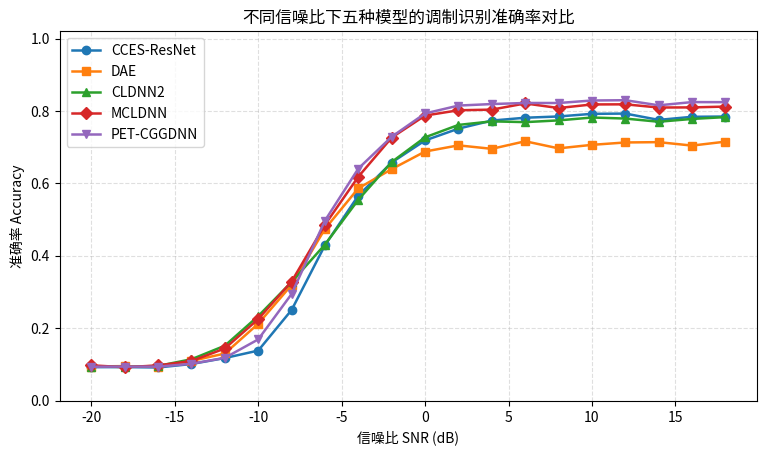

,CCES-ResNet,DAE,CLDNN2,MCLDNN,PET-CGGDNN
SNR(dB),,,,,
-20,0.0931,0.0950,0.0950,0.0982,0.0942
-18,0.0934,0.0961,0.0937,0.0930,0.0948
-16,0.0923,0.0937,0.0966,0.0979,0.0944
-14,0.1019,0.1102,0.1150,0.1100,0.1026
-12,0.1183,0.1309,0.1524,0.1447,0.1188
-10,0.1389,0.2130,0.2340,0.2257,0.1697
-8,0.2509,0.3200,0.3282,0.3295,0.2950
-6,0.4296,0.4748,0.4316,0.4862,0.4976
-4,0.5667,0.5868,0.5552,0.6188,0.6412


In [13]:
# ---------- 图 1：准确率 - 信噪比曲线 ----------
def acc_per_snr(model, snr_values):
    pred = predict_labels(model, X_te)
    return [accuracy_score(y_te[snr_te == s], pred[snr_te == s]) for s in snr_values]

import matplotlib.pyplot as plt
%matplotlib inline

acc_curves = {name: acc_per_snr(m, snrs) for name, m in models.items()}

plt.figure(figsize=(9, 4.8))
markers = ['o', 's', '^', 'D', 'v']
for (name, accs), mk in zip(acc_curves.items(), markers):
    plt.plot(snrs, accs, marker=mk, label=name, lw=1.8)
plt.xlabel('信噪比 SNR (dB)'); plt.ylabel('准确率 Accuracy')
plt.title('不同信噪比下五种模型的调制识别准确率对比')
plt.grid(True, ls='--', alpha=0.4); plt.legend(); plt.ylim(0, 1.02)
plt.show()

# 可直接放进论文的 SNR 对比表
snr_table = pd.DataFrame(acc_curves, index=snrs).round(4)
snr_table.index.name = 'SNR(dB)'
snr_table

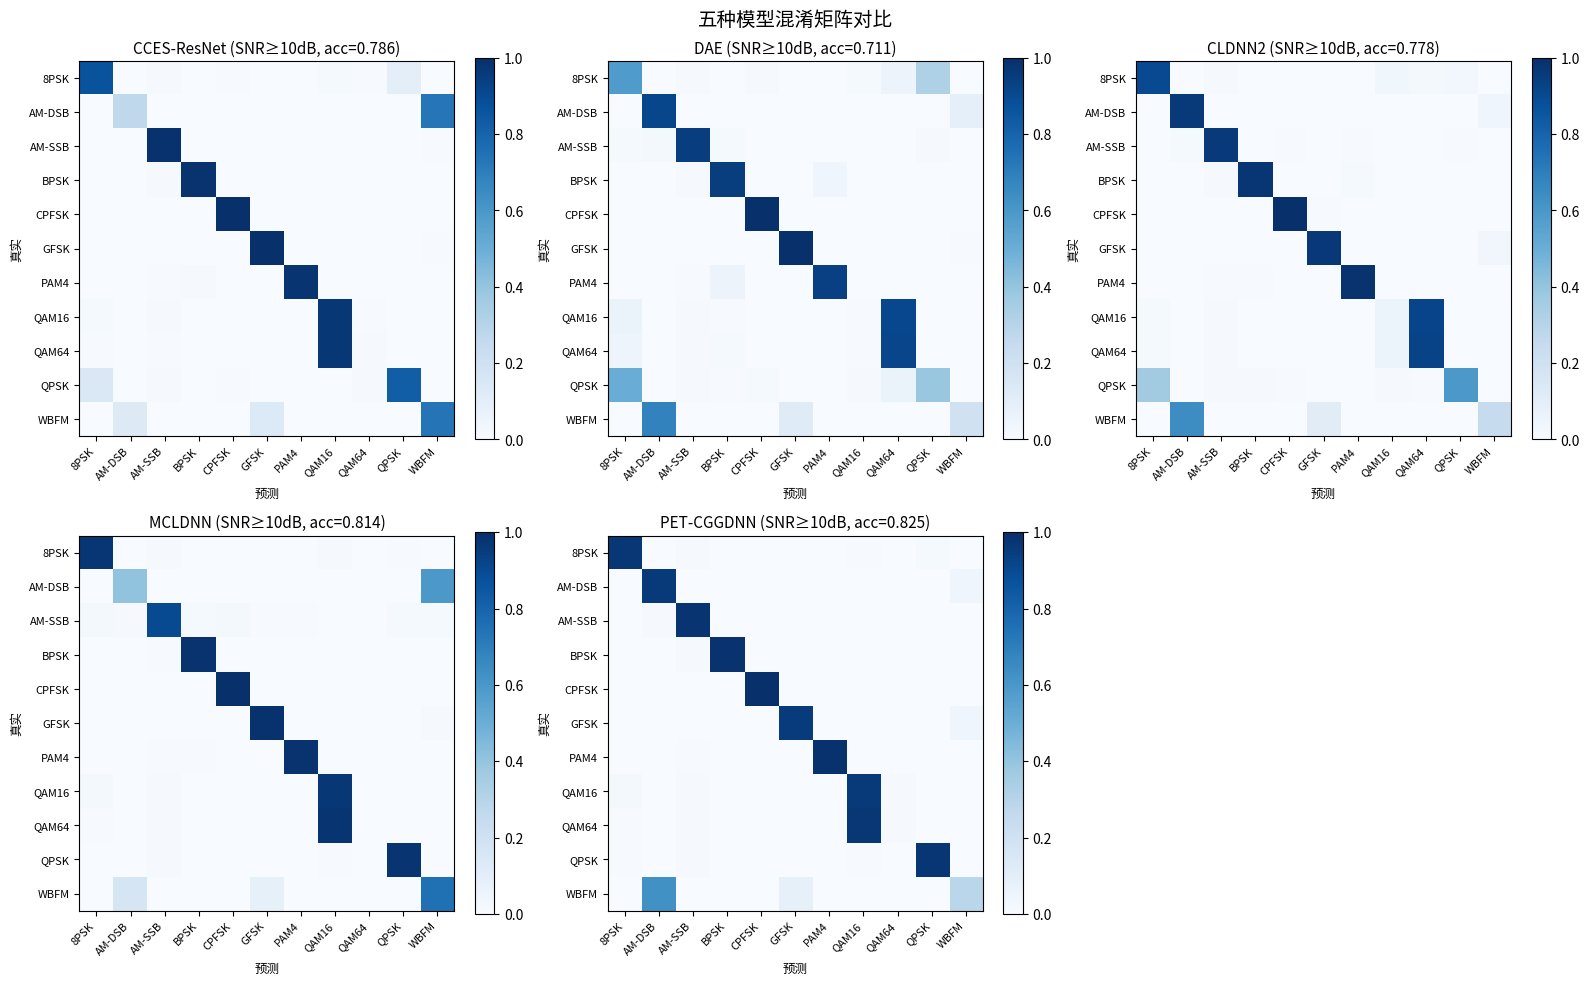

In [14]:
# ---------- 图 2：混淆矩阵对比（SNR ≥ 10 dB 子集） ----------
mask = snr_te >= 10
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()
for ax, (name, m) in zip(axes, models.items()):
    pred = predict_labels(m, X_te[mask])
    cm = confusion_matrix(y_te[mask], pred, normalize='true')
    im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
    ax.set_title(f'{name} (SNR≥10dB, acc={accuracy_score(y_te[mask], pred):.3f})', fontsize=11)
    ax.set_xticks(range(11)); ax.set_xticklabels(class_names, rotation=45, ha='right', fontsize=8)
    ax.set_yticks(range(11)); ax.set_yticklabels(class_names, fontsize=8)
    ax.set_xlabel('预测', fontsize=9); ax.set_ylabel('真实', fontsize=9)
    fig.colorbar(im, ax=ax, fraction=0.046)
for ax in axes[len(models):]: ax.axis('off')   # 隐藏多余子图
plt.suptitle('五种模型混淆矩阵对比', fontsize=14)
plt.tight_layout(); plt.show()

## 第 9 步 · 总结与论文对接

1. **对比实验的结论写法**：不要只说"我的方法最好"，要具体——"在 -4 dB 以下低信噪比区间，XX 模型准确率较基线提升 X 个百分点"（从图 1 左侧读数）；
2. **混淆矩阵的用途**：找到自己的方法减少的混淆对（如 QAM16↔QAM64），写进"讨论"部分；
3. **参数量表**：`count_params` 的结果可以做成一张参数量对比表，为论文的"轻量化/硬件部署展望"铺垫；
4. **通往创新点**：下一步在本 Notebook 基础上加两章实验即可对接论文——
   - 对表现最好的 base 模型做**数据增强**（小样本：每类 50 条，对比增强前后曲线）；
   - 做**迁移学习**（高 SNR 预训练 → 低 SNR 微调，对比从头训练）。
   这两组实验就是大纲第 4.4、4.5 节的全部内容。

### 📝 思考题
1. 为什么 MCLDNN 的单路视图对 QPSK/8PSK 这类相位调制可能更有效？
2. DAE 的重构损失为什么在小样本时帮助更大？（提示：正则化视角）
3. 从参数量和准确率两个维度看，哪个模型最适合"轻量化部署到硬件"这个故事？